# Camera student: teaching the camera policy from our teacher (DAgger)


## 1. Setup (same folder and branch as Phase 3)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, subprocess, json, glob, re, time
DRIVE_ROOT = "/content/drive/MyDrive/spirob_vision"
TEACH = f"{DRIVE_ROOT}/polar_teacher"          # teacher checkpoints + teacher evaluations
STU   = f"{DRIVE_ROOT}/camera_student"         # this notebook
REPO  = "/content/spirob-polar"
BRANCH = "origin/research/s2-spawn-randomization"
os.makedirs(STU, exist_ok=True)
if shutil.which("uv") is None:
    subprocess.run("curl -LsSf https://astral.sh/uv/install.sh | sh", shell=True, check=True)
    os.environ["PATH"] = f"/root/.local/bin:{os.environ['PATH']}"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "https://github.com/YADlin/spirob-mjlab", REPO], check=True)
os.chdir(REPO)
subprocess.run(["git", "fetch", "origin"], check=True)
subprocess.run(["git", "checkout", "-B", "polar-work", BRANCH], check=True)
subprocess.run(["uv", "sync"], check=True)
print(subprocess.run(["uv", "run", "python", "-c", "import torch; print('GPU:', torch.cuda.get_device_name(0))"],
                     capture_output=True, text=True).stdout)
print("already on Drive:", sorted(os.listdir(STU)))

## 2. Write the scripts 

In [ ]:
%%writefile /content/spirob-polar/tools/polar_tasks.py

from mjlab.managers.event_manager import EventTermCfg
from mjlab.managers.metrics_manager import MetricsTermCfg
from mjlab.tasks.registry import register_mjlab_task

import spirob_mjlab  # noqa: F401  (registers sir's tasks)
from spirob_mjlab import mdp
from spirob_mjlab.entities import movable_pedestal_cfg
from spirob_mjlab.env_cfgs import spirob_egg_to_bucket_stage1_env_cfg
from spirob_mjlab.rl_cfg import Stage2FineTuneRunner, spirob_ppo_runner_cfg

RADIUS_M = (0.120, 0.200)
POLAR_TASKS = {
    "Mjlab-SpiRob-Polar-Right": (RADIUS_M, (30.0, 80.0)),
    "Mjlab-SpiRob-Polar-Left": (RADIUS_M, (100.0, 150.0)),
    "Mjlab-SpiRob-Polar-Wide": (RADIUS_M, (30.0, 150.0)),
    "Mjlab-SpiRob-Polar-Arc15": ((0.139, 0.179), (50.8, 75.8)),   # halfway between sir's Arc-1 and Arc-2
}


def polar_env_cfg(radius_range_m, angle_range_deg, play=False):
    cfg = spirob_egg_to_bucket_stage1_env_cfg(play=play)
    if play:
        cfg.episode_length_s = 8.0
    cfg.scene.entities["pedestal"] = movable_pedestal_cfg()
    cfg.events["stage2_egg_pedestal_spawn"] = EventTermCfg(
        func=mdp.reset_stage2_sector_egg_and_pedestal,
        mode="reset",
        params={
            "radius_range_m": radius_range_m,
            "angle_range_deg": angle_range_deg,
            # 1 x 1 strata: a wide sector crosses the robot/bucket exclusion zones,
            # and fully-excluded strata would make stratified sampling fail
            "radial_strata": 1,
            "angular_strata": 1,
            "schedule_length": 10,
            "nominal_slots": 1,
            "retention_slots": 3,
            "max_resample_attempts": 256,
            "min_robot_centerline_clearance": 0.038,
            "min_bucket_center_clearance": 0.055,
        },
    )
    cfg.metrics = {
        "spawn_radius_mm": MetricsTermCfg(func=mdp.stage2_spawn_radius_mm, reduce="last"),
        "spawn_angle_deg": MetricsTermCfg(func=mdp.stage2_spawn_angle_deg, reduce="last"),
        "spawn_is_sector": MetricsTermCfg(func=mdp.stage2_spawn_is_sector, reduce="last"),
        "spawn_rejection_count": MetricsTermCfg(func=mdp.stage2_spawn_rejection_count, reduce="last"),
    }
    return cfg


for _task_id, (_r, _th) in POLAR_TASKS.items():
    register_mjlab_task(
        task_id=_task_id,
        env_cfg=polar_env_cfg(_r, _th, play=False),
        play_env_cfg=polar_env_cfg(_r, _th, play=True),
        rl_cfg=spirob_ppo_runner_cfg(stage2=True),
        runner_cls=Stage2FineTuneRunner,
    )

In [ ]:
%%writefile /content/spirob-polar/tools/polar_check.py

import sys, os, json, time, argparse, math
from dataclasses import asdict
sys.path.insert(0, "/content/spirob-polar/tools")
import numpy as np
import torch
from tensordict import TensorDict
import polar_tasks  # noqa: F401  (registers the polar tasks)
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg, load_runner_cls

ap = argparse.ArgumentParser()
ap.add_argument("--mode", choices=["spawns", "eval"], required=True)
ap.add_argument("--task", default="Mjlab-SpiRob-Polar-Wide")
ap.add_argument("--out", required=True)
ap.add_argument("--ws", default="", help="workspace_map folder, for the background map")
ap.add_argument("--num_envs", type=int, default=512)
ap.add_argument("--rounds", type=int, default=3)
ap.add_argument("--checkpoint", default="")
ap.add_argument("--label", default="policy")
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
DEV = "cuda:0"
BUCKET = (-0.05, 0.15)
GROUP = {0: "nominal", 1: "retention", 2: "sector"}


def make_env():
    cfg = load_env_cfg(a.task, play=False)
    cfg.scene.num_envs = a.num_envs
    cfg.auto_reset = False
    cfg.seed = 1001
    cfg.observations["actor"].enable_corruption = False
    cfg.observations["critic"].enable_corruption = False
    env = ManagerBasedRlEnv(cfg=cfg, device=DEV)
    vec = RslRlVecEnvWrapper(env, clip_actions=load_rl_cfg(a.task).clip_actions)
    return env, vec


def spawn_info(env):
    egg = env.scene["egg"].data.root_link_pos_w - env.scene.env_origins
    grp = getattr(env, "_stage2_spawn_group", torch.full((env.num_envs,), -1, device=DEV))
    return egg[:, :2].clone(), egg[:, 2].clone(), grp.clone()


def flags(env):
    tm = env.termination_manager
    g = lambda n: tm.get_term(n).bool()
    return g("success_egg_inside_bucket"), g("egg_fell") | g("egg_oob"), g("nan_state")


def run_round(env, vec, policy, steps):
    """One synchronous batch: every env runs one episode; finished envs are reset and masked."""
    vec.reset()
    xy, z0, grp = spawn_info(env)
    obs = TensorDict(env.observation_manager.compute(update_history=True), batch_size=[env.num_envs])
    N = env.num_envs
    done = torch.zeros(N, dtype=torch.bool, device=DEV)
    succ, fell, crash = done.clone(), done.clone(), done.clone()
    min_z = z0.clone()
    for t in range(steps):
        with torch.no_grad():
            act = policy(obs) if policy is not None else torch.zeros((N, 2), device=DEV)
        obs, _, dones, _ = vec.step(act)
        ez = env.scene["egg"].data.root_link_pos_w[:, 2]
        min_z = torch.where(done, min_z, torch.minimum(min_z, ez))
        s, f, n = flags(env)
        new = ~done & (s | f | n)
        succ |= new & s; fell |= new & f & ~s; crash |= new & n & ~s
        done |= new
        if bool(done.all()):
            break
        ended = torch.nonzero(dones.bool()).flatten()
        if len(ended):
            env.reset(env_ids=ended)
    return dict(xy=xy.cpu().numpy(), z0=z0.cpu().numpy(), group=grp.cpu().numpy(),
                success=succ.cpu().numpy(), fell=fell.cpu().numpy(), crash=crash.cpu().numpy(),
                drop_mm=((z0 - min_z) * 1000).cpu().numpy())


def background(ax):
    import matplotlib.pyplot as plt
    LIM, CELL = 0.35, 0.005
    NC = int(round(2 * LIM / CELL))
    grid = np.zeros(NC * NC)
    for f in ("hold.npz", "random.npz"):
        p = os.path.join(a.ws, f)
        if a.ws and os.path.isfile(p):
            grid += np.load(p)["body"]
    if grid.any():
        ax.imshow(np.log1p(grid.reshape(NC, NC)), origin="lower", extent=[-LIM, LIM, -LIM, LIM],
                  cmap="Greys", alpha=0.6)
    for rr in (0.12, 0.20):
        ax.add_patch(plt.Circle((0, 0), rr, fill=False, ls="--", lw=0.8, color="tab:blue"))
    ax.add_patch(plt.Circle(BUCKET, 0.055, fill=False, lw=1, color="red"))
    ax.axvspan(-0.038, 0.038, color="orange", alpha=0.12)
    ax.plot(*BUCKET, "s", color="red", label="bucket (+55 mm exclusion)")
    ax.plot(0, 0, "k+", ms=10, label="robot base")
    ax.set_xlim(-0.25, 0.25); ax.set_ylim(-0.02, 0.26); ax.set_aspect("equal")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")


def polar(xy):
    return np.hypot(xy[:, 0], xy[:, 1]) * 1000, np.degrees(np.arctan2(xy[:, 1], xy[:, 0]))


import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

if a.mode == "spawns":
    env, vec = make_env()
    rows = [run_round(env, vec, None, 150) for _ in range(a.rounds)]   # robot held still, 1.5 s
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    stable = (~R["fell"]) & (~R["crash"]) & (R["drop_mm"] < 5)
    print(f"{a.task}: {len(r_mm)} spawns")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            print(f"  {name:9s}: {m.sum():5d} spawns | r {r_mm[m].min():5.0f}-{r_mm[m].max():5.0f} mm | "
                  f"theta {th[m].min():5.1f}-{th[m].max():5.1f} deg | egg stays on pedestal {stable[m].mean():.0%}")
    bd = np.hypot(R["xy"][:, 0] - BUCKET[0], R["xy"][:, 1] - BUCKET[1]) * 1000
    print(f"  closest spawn to bucket centre: {bd.min():.0f} mm (must be >= 55) | "
          f"closest to robot centreline: {np.abs(R['xy'][:, 0]).min() * 1000:.0f} mm (must be >= 38)")
    print(f"  ALL spawns stable: {bool(stable.all())}  ({(~stable).sum()} unstable)")
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    ax.scatter(R["xy"][stable, 0], R["xy"][stable, 1], s=4, c="tab:green", label="spawn, egg stays")
    if (~stable).any():
        ax.scatter(R["xy"][~stable, 0], R["xy"][~stable, 1], s=12, c="tab:red", marker="x", label="egg fell / crash")
    ax.set_title(f"{a.task}: spawns over the workspace map"); ax.legend(fontsize=7, loc="upper left")
    plt.tight_layout(); f = f"{a.out}/spawns_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

else:  # eval
    assert a.checkpoint and os.path.isfile(a.checkpoint), "give --checkpoint"
    env, vec = make_env()
    agent_cfg = load_rl_cfg(a.task)
    runner_cls = load_runner_cls(a.task) or MjlabOnPolicyRunner
    runner = runner_cls(vec, asdict(agent_cfg), device=DEV)
    runner.load(a.checkpoint, load_cfg={"actor": True}, strict=True, map_location=DEV)
    policy = runner.get_inference_policy(device=DEV)
    T = int(env.max_episode_length) + 1
    rows = []
    for i in range(a.rounds):
        t0 = time.time()
        rows.append(run_round(env, vec, policy, T))
        print(f"round {i + 1}/{a.rounds}: {time.time() - t0:.0f}s, success {rows[-1]['success'].mean():.0%}", flush=True)
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    out = {"task": a.task, "checkpoint": a.checkpoint, "label": a.label, "groups": {}, "by_angle": []}
    print(f"\n{a.label} on {a.task}")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            out["groups"][name] = {"n": int(m.sum()), "success": float(R["success"][m].mean()),
                                   "fell": float(R["fell"][m].mean())}
            print(f"  {name:9s}: success {R['success'][m].mean():5.0%}  fell {R['fell'][m].mean():5.0%}  (n={m.sum()})")
    sec = R["group"] == 2
    print("\n  sector spawns by angle:\n  theta (deg) |   n  | success | fell")
    for lo in range(30, 150, 10):
        m = sec & (th >= lo) & (th < lo + 10)
        if m.any():
            out["by_angle"].append({"theta": lo, "n": int(m.sum()), "success": float(R["success"][m].mean()),
                                    "fell": float(R["fell"][m].mean())})
            print(f"   {lo:3d}-{lo + 10:3d}   | {m.sum():4d} | {R['success'][m].mean():6.0%}  | {R['fell'][m].mean():4.0%}")
    json.dump(out, open(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.json", "w"), indent=1)
    np.savez(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.npz", **R)
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    col = np.where(R["success"], "tab:green", np.where(R["fell"], "tab:red", "tab:gray"))
    ax.scatter(R["xy"][:, 0], R["xy"][:, 1], s=5, c=col)
    ax.set_title(f"{a.label} on {a.task}: green = success, red = fell, grey = timeout")
    plt.tight_layout(); f = f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

In [ ]:
%%writefile /content/spirob-polar/tools/student_dagger.py

import sys, os, json, time, math, argparse
from dataclasses import asdict, dataclass
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tensordict import TensorDict
import polar_tasks  # noqa: F401  (registers the polar tasks)
from polar_tasks import polar_env_cfg
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.sensor import CameraSensor, CameraSensorCfg
from mjlab.tasks.registry import load_rl_cfg, load_runner_cls

ap = argparse.ArgumentParser()
ap.add_argument("--mode", choices=["check", "train", "eval"], required=True)
ap.add_argument("--out", required=True, help="Drive folder for students, logs, pictures")
ap.add_argument("--task", default="Mjlab-SpiRob-Polar-Arc15", help="polar task (spawn ranges + teacher runner cfg)")
ap.add_argument("--teacher", default="", help="teacher checkpoint (train mode)")
ap.add_argument("--num_envs", type=int, default=256)
ap.add_argument("--rounds", type=int, default=10)
ap.add_argument("--betas", default="1,0.5,0.3,0.2,0.1,0", help="share of envs driven by the teacher, per round (last value repeats)")
ap.add_argument("--rec_every", type=int, default=3, help="record every k-th step")
ap.add_argument("--max_samples", type=int, default=150000, help="dataset cap (GPU memory)")
ap.add_argument("--train_steps", type=int, default=1500)
ap.add_argument("--first_train_steps", type=int, default=3000)
ap.add_argument("--batch", type=int, default=256)
ap.add_argument("--lr", type=float, default=3e-4)
ap.add_argument("--no_keypoints", action="store_true", help="also hide the arm-shape keypoints from the student")
ap.add_argument("--resume", action="store_true", help="train: continue from student_last.pt in --out")
ap.add_argument("--student", default="", help="eval: student checkpoint")
ap.add_argument("--label", default="student")
ap.add_argument("--ablate", choices=["none", "black", "frozen"], default="none")
ap.add_argument("--eval_rounds", type=int, default=2)
ap.add_argument("--cam_w", type=int, default=80)
ap.add_argument("--cam_h", type=int, default=60)
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
DEV = "cuda:0"
CAM = "overhead_cam"
GROUP = {0: "nominal", 1: "retention", 2: "sector"}
torch.manual_seed(0)

# teacher actor observation layout (93): tendon_len 0:2 | tendon_vel 2:4 | egg_to_bucket 4:7 |
# last_action 7:9 | robot_keypoints_xy 9:51 | touch 51:93
EGG = slice(4, 7)
HIDE = set(range(4, 7)) | (set(range(9, 51)) if a.no_keypoints else set())
KEEP = [i for i in range(93) if i not in HIDE]

@dataclass
class RobotCamCfg(CameraSensorCfg):
    """Camera fixed to the robot's base frame, so every parallel env gets its own view."""
    def build(self):
        return RobotCam(self)


class RobotCam(CameraSensor):
    def edit_spec(self, scene_spec, entities):
        names = [b.name for b in scene_spec.bodies]
        parent = next((n for n in ("robot/mocap_base", "robot/robot_base") if n in names), None)
        if parent is None:
            raise RuntimeError(f"no robot base body found; bodies: {names[:15]}")
        print(f"[camera] attached to body '{parent}'", flush=True)
        self.cfg.parent_body = parent
        super().edit_spec(scene_spec, entities)


def make_env(n):
    r, th = polar_tasks.POLAR_TASKS[a.task]
    cfg = polar_env_cfg(r, th, play=False)
    # straight down, centred over the bucket + spawn arc; ~4.5 mm per pixel at egg height
    cam = RobotCamCfg(name=CAM, pos=(0.06, 0.135, 0.50), quat=(1.0, 0.0, 0.0, 0.0), fovy=34.0,
                      width=a.cam_w, height=a.cam_h, data_types=("rgb",))
    cfg.scene.sensors = tuple(cfg.scene.sensors or ()) + (cam,)
    cfg.scene.num_envs = n
    cfg.auto_reset = False
    cfg.seed = 1001 if a.mode == "eval" else int(time.time()) % 100000
    cfg.observations["actor"].enable_corruption = False
    cfg.observations["critic"].enable_corruption = False
    env = ManagerBasedRlEnv(cfg=cfg, device=DEV)
    vec = RslRlVecEnvWrapper(env, clip_actions=load_rl_cfg(a.task).clip_actions)
    return env, vec


def image(env):
    return env.scene[CAM].data.rgb.permute(0, 3, 1, 2).contiguous()      # (N, 3, H, W) uint8


def flags(env):
    tm = env.termination_manager
    g = lambda n: tm.get_term(n).bool()
    return g("success_egg_inside_bucket"), g("egg_fell") | g("egg_oob"), g("nan_state")


def spawn_info(env):
    xy = (env.scene["egg"].data.root_link_pos_w - env.scene.env_origins)[:, :2].clone()
    grp = getattr(env, "_stage2_spawn_group", torch.full((env.num_envs,), -1, device=DEV)).clone()
    return xy, grp


def load_teacher(vec, path):
    runner_cls = load_runner_cls(a.task) or MjlabOnPolicyRunner
    runner = runner_cls(vec, asdict(load_rl_cfg(a.task)), device=DEV)
    runner.load(path, load_cfg={"actor": True}, strict=True, map_location=DEV)
    return runner.get_inference_policy(device=DEV)


class SpatialSoftmax(nn.Module):
    """Turns each feature map into the (x, y) image position where it is most active."""
    def __init__(self, h, w):
        super().__init__()
        ys, xs = torch.meshgrid(torch.linspace(-1, 1, h), torch.linspace(-1, 1, w), indexing="ij")
        self.register_buffer("xs", xs.reshape(-1))
        self.register_buffer("ys", ys.reshape(-1))
        self.log_temp = nn.Parameter(torch.zeros(1))

    def forward(self, f):
        B, K, h, w = f.shape
        p = torch.softmax(f.reshape(B, K, h * w) / self.log_temp.exp(), -1)
        return torch.cat([(p * self.xs).sum(-1), (p * self.ys).sum(-1)], -1)


class Student(nn.Module):
    def __init__(self, n_prop, h, w, n_kp=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 5, 1, 2), nn.ELU(),
            nn.Conv2d(32, 32, 3, 2, 1), nn.ELU(),
            nn.Conv2d(32, 64, 3, 1, 1), nn.ELU())
        self.kp = nn.Conv2d(64, n_kp, 3, 1, 1)
        with torch.no_grad():
            fh, fw = self.conv(torch.zeros(1, 3, h, w)).shape[-2:]
        self.ssm = SpatialSoftmax(fh, fw)
        n_img = 2 * n_kp + 64
        self.mlp = nn.Sequential(nn.Linear(n_img + n_prop, 256), nn.ELU(),
                                 nn.Linear(256, 256), nn.ELU(), nn.Linear(256, 2))
        self.aux = nn.Sequential(nn.Linear(n_img, 128), nn.ELU(), nn.Linear(128, 3))   # egg position from image only
        self.register_buffer("p_mean", torch.zeros(n_prop))
        self.register_buffer("p_std", torch.ones(n_prop))

    def features(self, img_u8):
        f = self.conv(img_u8.float() / 255.0 - 0.5)
        return torch.cat([self.ssm(self.kp(f)), f.mean((-2, -1))], -1)

    def forward(self, img_u8, prop):
        z = self.features(img_u8)
        p = (prop - self.p_mean) / self.p_std
        return self.mlp(torch.cat([z, p], -1)), self.aux(z)


def act_loss(pred, tgt):
    """Actions beyond +-1 all mean 'cable at its limit'. Match the effective command,
    plus a small pull toward the teacher's raw value (it feeds back as 'last action')."""
    t = tgt.clamp(-1, 1)
    err = (pred - t) ** 2
    same_side = ((t >= 1 - 1e-4) & (pred >= 1)) | ((t <= -1 + 1e-4) & (pred <= -1))
    return torch.where(same_side, torch.zeros_like(err), err).mean() + 0.02 * F.smooth_l1_loss(pred, tgt)


def run_round(env, vec, teacher, student, beta, record, ablate="none"):
    N = env.num_envs
    vec.reset()
    obs = TensorDict(env.observation_manager.compute(update_history=True), batch_size=[N])
    xy, grp = spawn_info(env)
    by_teacher = torch.rand(N, device=DEV) < beta
    first_img = image(env).clone()
    T = int(env.max_episode_length) + 1
    done = torch.zeros(N, dtype=torch.bool, device=DEV)
    succ, fell, crash = done.clone(), done.clone(), done.clone()
    buf = {"img": [], "prop": [], "act": [], "egg": []}
    egg_err = []
    for t in range(T):
        img = image(env)
        if ablate == "black":
            img = torch.zeros_like(img)
        elif ablate == "frozen":
            img = first_img
        ob = obs["actor"]
        with torch.no_grad():
            a_t = teacher(obs) if teacher is not None else None
            if student is not None:
                a_s, egg_hat = student(img, ob[:, KEEP])
                egg_err.append(((egg_hat / 10 - ob[:, EGG]).norm(dim=-1))[~done])
            act = a_s if a_t is None else (a_t if student is None else torch.where(by_teacher[:, None], a_t, a_s))
        if record and t % a.rec_every == 0:
            m = ~done
            buf["img"].append(img[m].clone()); buf["prop"].append(ob[m][:, KEEP].clone())
            buf["act"].append(a_t[m].clone()); buf["egg"].append(ob[m][:, EGG].clone() * 10)
        obs, _, dones, _ = vec.step(act)
        s, f, n = flags(env)
        new = ~done & (s | f | n)
        succ |= new & s; fell |= new & f & ~s; crash |= new & n & ~s
        done |= new
        if bool(done.all()):
            break
        ended = torch.nonzero(dones.bool()).flatten()
        if len(ended):
            env.reset(env_ids=ended)
    data = {k: torch.cat(v) for k, v in buf.items()} if record else None
    res = dict(xy=xy.cpu().numpy(), group=grp.cpu().numpy(), by_teacher=by_teacher.cpu().numpy(),
               success=succ.cpu().numpy(), fell=fell.cpu().numpy(), crash=crash.cpu().numpy(),
               egg_err_mm=float(torch.cat(egg_err).mean() * 1000) if egg_err else float("nan"))
    return res, data


def table(R, mask, title):
    th = np.degrees(np.arctan2(R["xy"][:, 1], R["xy"][:, 0]))
    out = {"groups": {}, "by_angle": []}
    print(f"  {title}")
    for g, name in GROUP.items():
        m = mask & (R["group"] == g)
        if m.any():
            out["groups"][name] = {"n": int(m.sum()), "success": float(R["success"][m].mean()), "fell": float(R["fell"][m].mean())}
            print(f"    {name:9s}: success {R['success'][m].mean():5.0%}  fell {R['fell'][m].mean():5.0%}  (n={m.sum()})")
    sec = mask & (R["group"] == 2)
    for lo in range(30, 150, 10):
        m = sec & (th >= lo) & (th < lo + 10)
        if m.any():
            out["by_angle"].append({"theta": lo, "n": int(m.sum()), "success": float(R["success"][m].mean())})
            print(f"      sector {lo:3d}-{lo + 10:3d} deg: success {R['success'][m].mean():5.0%}  (n={m.sum()})")
    return out

if a.mode == "check":
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    env, vec = make_env(8)
    vec.reset()
    img = image(env).permute(0, 2, 3, 1).cpu().numpy()
    xy, grp = spawn_info(env)
    obs = env.observation_manager.compute(update_history=True)
    print("camera image batch:", tuple(img.shape), "dtype", img.dtype, "| pixel range", img.min(), "-", img.max())
    print("teacher observation size:", obs["actor"].shape[-1], "| student sees", len(KEEP), "numbers + the image")
    fig, axs = plt.subplots(2, 4, figsize=(14, 6))
    for i, ax in enumerate(axs.flat):
        x, y = xy[i].tolist()
        ax.imshow(img[i], interpolation="nearest")
        ax.set_title(f"egg r={math.hypot(x, y) * 1000:.0f} mm, th={math.degrees(math.atan2(y, x)):.0f} deg", fontsize=9)
        ax.axis("off")
    plt.suptitle("overhead camera: what the student sees (each tile = one env)")
    plt.tight_layout()
    f = f"{a.out}/camera_check.png"
    plt.savefig(f, dpi=110)
    print("saved", f)

elif a.mode == "train":
    env, vec = make_env(a.num_envs)
    H, W = a.cam_h, a.cam_w
    assert a.teacher and os.path.isfile(a.teacher), "give --teacher"
    teacher = load_teacher(vec, a.teacher)
    student = Student(len(KEEP), H, W).to(DEV)
    opt = torch.optim.Adam(student.parameters(), lr=a.lr)
    betas = [float(b) for b in a.betas.split(",")]
    log_path = f"{a.out}/train_log.json"
    log, start = [], 0
    if a.resume and os.path.isfile(f"{a.out}/student_last.pt"):
        ck = torch.load(f"{a.out}/student_last.pt", map_location=DEV, weights_only=False)
        student.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        start = ck["round"] + 1
        log = json.load(open(log_path)) if os.path.isfile(log_path) else []
        print(f"resumed after round {ck['round']} (dataset starts empty again)", flush=True)
    D = None
    print(f"student input: {H}x{W} image + {len(KEEP)} numbers (hidden: egg position"
          f"{', arm keypoints' if a.no_keypoints else ''}) | teacher: {a.teacher}", flush=True)
    for rd in range(start, a.rounds):
        beta = betas[min(rd, len(betas) - 1)]
        t0 = time.time()
        R, data = run_round(env, vec, teacher, student if (rd > 0 or start > 0) else None, beta, record=True)
        t_roll = time.time() - t0
        # grow the dataset (random thinning when it passes the cap)
        D = data if D is None else {k: torch.cat([D[k], data[k]]) for k in D}
        n = len(D["act"])
        if n > a.max_samples:
            keep = torch.randperm(n, device=DEV)[: a.max_samples]
            D = {k: v[keep] for k, v in D.items()}
            n = a.max_samples
        if rd == start and not a.resume:
            student.p_mean.copy_(D["prop"].mean(0)); student.p_std.copy_(D["prop"].std(0).clamp(min=1e-2))
        # train
        steps = a.first_train_steps if rd == start else a.train_steps
        t1, la, le = time.time(), [], []
        student.train()
        for s in range(steps):
            i = torch.randint(n, (a.batch,), device=DEV)
            pred, egg_hat = student(D["img"][i], D["prop"][i])
            l_act = act_loss(pred, D["act"][i])
            l_egg = F.mse_loss(egg_hat, D["egg"][i])
            loss = l_act + l_egg
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(student.parameters(), 1.0); opt.step()
            la.append(l_act.item()); le.append(l_egg.item())
        student.eval()
        egg_mm = math.sqrt(np.mean(le[-200:]) * 3) * 100      # rms egg-position error of the image head, mm
        stu = ~R["by_teacher"]
        row = {"round": rd, "beta": beta, "samples": n, "rollout_s": round(t_roll), "train_s": round(time.time() - t1),
               "action_loss": float(np.mean(la[-200:])), "egg_err_train_mm": egg_mm,
               "teacher_success": float(R["success"][R["by_teacher"]].mean()) if R["by_teacher"].any() else None,
               "student_success": float(R["success"][stu].mean()) if (stu.any() and rd > 0) else None,
               "student_egg_err_mm": R["egg_err_mm"]}
        log.append(row)
        ts = "-" if row["teacher_success"] is None else f"{row['teacher_success']:.0%}"
        ss = "-" if row["student_success"] is None else f"{row['student_success']:.0%}"
        print(f"round {rd + 1:2d}/{a.rounds} | teacher share {beta:.0%} | success: teacher-driven {ts:>4}, "
              f"student-driven {ss:>4} | egg found within ~{egg_mm:4.1f} mm | action loss {row['action_loss']:.3f} | "
              f"data {n} | {t_roll:.0f}s + {row['train_s']}s", flush=True)
        ck = {"model": student.state_dict(), "opt": opt.state_dict(), "round": rd, "keep": KEEP,
              "cam": (H, W), "no_keypoints": a.no_keypoints, "teacher": a.teacher}
        torch.save(ck, f"{a.out}/student_round{rd + 1:02d}.pt")
        torch.save(ck, f"{a.out}/student_last.pt")
        json.dump(log, open(log_path, "w"), indent=1)
    print("saved", f"{a.out}/student_last.pt")

else:  # eval
    assert a.student and os.path.isfile(a.student), "give --student"
    ck = torch.load(a.student, map_location=DEV, weights_only=False)
    assert ck["keep"] == KEEP, "use the same --no_keypoints setting as in training"
    env, vec = make_env(a.num_envs)
    student = Student(len(KEEP), *ck["cam"]).to(DEV)
    student.load_state_dict(ck["model"]); student.eval()
    rows = []
    for i in range(a.eval_rounds):
        t0 = time.time()
        R, _ = run_round(env, vec, None, student, 0.0, record=False, ablate=a.ablate)
        rows.append(R)
        print(f"round {i + 1}/{a.eval_rounds}: {time.time() - t0:.0f}s, success {R['success'].mean():.0%}", flush=True)
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0] if k != "egg_err_mm"}
    err = float(np.mean([r["egg_err_mm"] for r in rows]))
    print(f"\n{a.label} on {a.task} (image: {a.ablate}) | camera egg-position error {err:.1f} mm")
    out = table(R, np.ones(len(R["success"]), bool), "student alone")
    out.update({"label": a.label, "ablate": a.ablate, "egg_err_mm": err, "student": a.student})
    f = f"{a.out}/eval_{a.label}_{a.ablate}.json"
    json.dump(out, open(f, "w"), indent=1)
    print("saved", f)

In [ ]:
!python -m py_compile /content/spirob-polar/tools/polar_tasks.py /content/spirob-polar/tools/polar_check.py /content/spirob-polar/tools/student_dagger.py && echo "OK - no syntax errors"

## 3. Helpers + choose the teacher


In [ ]:
from IPython.display import Image, display

def _ck_num(p):
    m = re.findall(r"model_(\d+)\.pt$", p); return int(m[0]) if m else -1

def last_ckpt(stage):
    cks = sorted([p for p in glob.glob(f"{TEACH}/{stage}/model_*.pt") if _ck_num(p) >= 0], key=_ck_num)
    return cks[-1] if cks else None

def stu(*args, show_all=False):
    """Run student_dagger.py in this cell, printing its progress lines as they come."""
    cmd = ["uv", "run", "python", "tools/student_dagger.py", "--out", STU] + [str(x) for x in args]
    p = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    tail = []
    for line in p.stdout:
        tail = (tail + [line])[-60:]
        if show_all or line.startswith(("round", "student", "  ", "saved", "resumed", "camera", "teacher", "[camera]")) \
                or "Error" in line or "error" in line or "Traceback" in line:
            print(line.rstrip(), flush=True)
    p.wait()
    if p.returncode != 0:
        print("".join(tail)); raise RuntimeError(f"student_dagger failed (exit {p.returncode})")

TEACHER = last_ckpt("stageA15c") or last_ckpt("stageA15b")
print("teacher:", TEACHER)
for f in sorted(glob.glob(f"{TEACH}/eval_stageA15*_Arc15.json")):
    d = json.load(open(f)); g = d["groups"]
    print(f"  {os.path.basename(f)}: nominal {g['nominal']['success']:.0%}, retention {g['retention']['success']:.0%}, "
          f"sector {g['sector']['success']:.0%}")

## 4. Camera check

Setting seed: 2500
Warp 1.14.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
[camera] attached to body 'robot/mocap_base'
Module mujoco_warp._src.smooth cf7a289 load on device 'cuda:0' took 9277.84 ms  (compiled)
Module mujoco_warp._src.collision_driver 621a3f9 load on device 'cuda:0' took 141.51 ms  (compiled)
Module _nxn_broadphase__locals__kernel_4ee3649d 4ee3649 load on device 'cuda:0' took 589.86 ms  (compiled)
Module ccd_kernel_builder__locals__ccd_kernel_c1aa383f c1aa383 load on device 'cuda:0' took 18670.25 ms  (compiled)
Module ccd_kernel_builder__locals__ccd_kernel_85133f97 85133f9 load on device 'cuda:0' took 17893.71 ms  (compiled)
Module ccd_kernel_builder__locals__ccd_kernel_15a19499 15a1949 load on device 'cuda:0' took 19924.78 ms  (compiled)
Module ccd_kernel_builder__locals__ccd_kernel_713b615b 713b615 load on device 'cuda

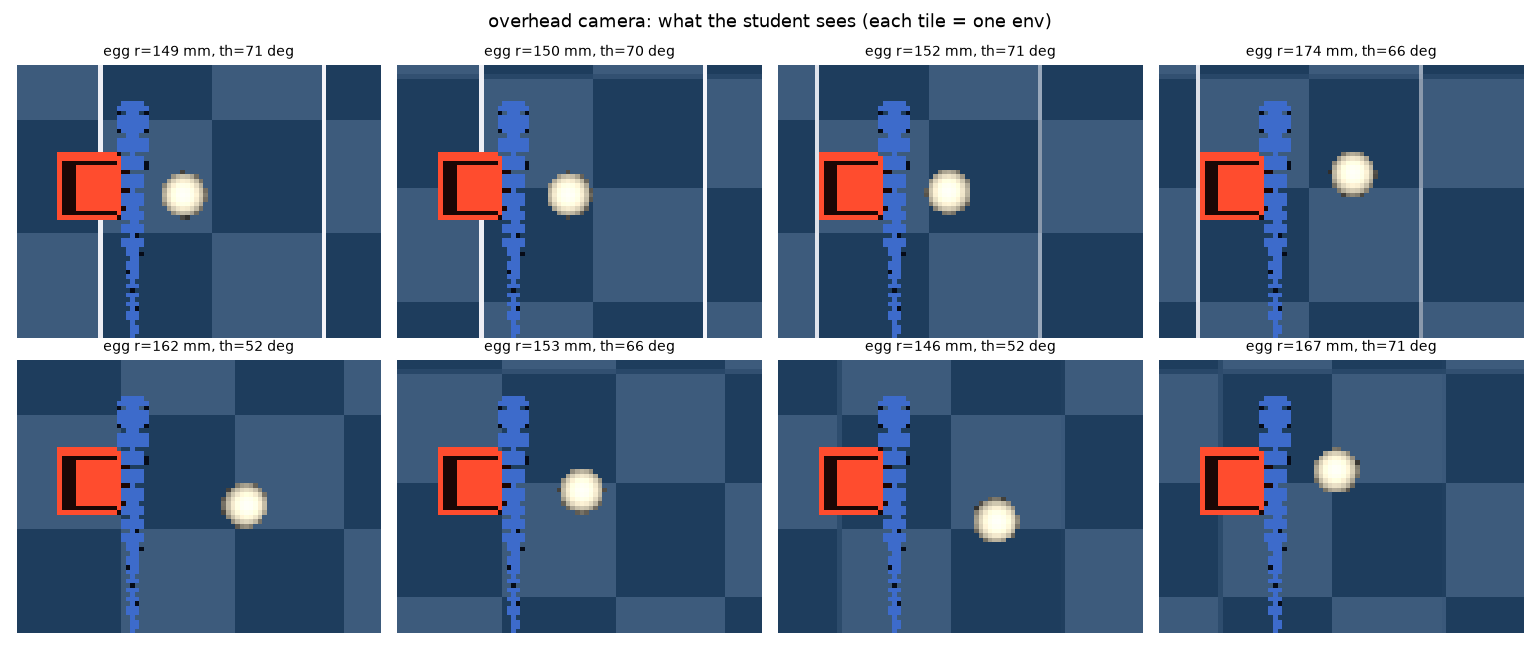

In [ ]:
stu("--mode", "check", show_all=True)
display(Image(f"{STU}/camera_check.png", width=900))

## 5. DAgger training



In [ ]:
stu("--mode", "train", "--teacher", TEACHER, "--num_envs", 256, "--rounds", 10)

   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
[camera] attached to body 'robot/mocap_base'
  (obs_normalizer): EmpiricalNormalization()
  (distribution): GaussianDistribution()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
  (obs_normalizer): EmpiricalNormalization()
  (mlp): MLP(
    (0): Linear(in_features=93, out_features=128, bias=True)
    (1): ELU(alpha=1.0)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ELU(alpha=1.0)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
student input: 60x80 image + 90 numbers (hidden: egg position) | teacher: /content/drive/MyDrive/spirob_vision/polar_teacher/stageA15c/model_499

In [ ]:
P = "/content/spirob-polar/tools/student_dagger.py"
s = open(P).read()
s = s.replace('choices=["none", "black", "frozen"]', 'choices=["none", "black", "frozen", "swap"]')
s = s.replace('''        elif ablate == "frozen":
            img = first_img''', '''        elif ablate == "frozen":
            img = first_img
        elif ablate == "swap":
            img = img.roll(N // 2, dims=0)     # each robot sees another robot's camera (egg elsewhere)''')
open(P, "w").write(s)
import py_compile; py_compile.compile(P, doraise=True)
print("swap test added:", '"swap"' in s and "img.roll" in s)

## 6. Evaluate the student, then prove it uses the camera

In [ ]:
STUDENT = f"{STU}/student_last.pt"
stu("--mode", "eval", "--student", STUDENT, "--label", "student", "--ablate", "none")

   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
[camera] attached to body 'robot/mocap_base'
round 1/2: 309s, success 62%
round 2/2: 306s, success 52%
student on Mjlab-SpiRob-Polar-Arc15 (image: none) | camera egg-position error 4.5 mm
  student alone
    nominal  : success   86%  fell    0%  (n=51)
    retention: success   82%  fell    2%  (n=124)
    sector   : success   43%  fell   27%  (n=337)
      sector  50- 60 deg: success   29%  (n=121)
      sector  60- 70 deg: success   51%  (n=142)
      sector  70- 80 deg: success   51%  (n=74)
saved /content/drive/MyDrive/spirob_vision/camera_student/eval_student_none.json


In [ ]:
stu("--mode", "eval", "--student", STUDENT, "--label", "student", "--ablate", "black")

   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
[camera] attached to body 'robot/mocap_base'
round 1/2: 300s, success 37%
round 2/2: 300s, success 31%
student on Mjlab-SpiRob-Polar-Arc15 (image: black) | camera egg-position error 61.4 mm
  student alone
    nominal  : success   77%  fell    2%  (n=48)
    retention: success   56%  fell   18%  (n=168)
    sector   : success   15%  fell   69%  (n=296)
      sector  50- 60 deg: success    0%  (n=103)
      sector  60- 70 deg: success   17%  (n=131)
      sector  70- 80 deg: success   34%  (n=62)
saved /content/drive/MyDrive/spirob_vision/camera_student/eval_student_black.json


In [ ]:
stu("--mode", "eval", "--student", STUDENT, "--label", "student", "--ablate", "swap")

   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
[camera] attached to body 'robot/mocap_base'
round 1/2: 305s, success 45%
round 2/2: 306s, success 40%
student on Mjlab-SpiRob-Polar-Arc15 (image: swap) | camera egg-position error 47.3 mm
  student alone
    nominal  : success   69%  fell   14%  (n=51)
    retention: success   60%  fell   19%  (n=156)
    sector   : success   29%  fell   51%  (n=305)
      sector  50- 60 deg: success   26%  (n=103)
      sector  60- 70 deg: success   29%  (n=129)
      sector  70- 80 deg: success   32%  (n=73)
saved /content/drive/MyDrive/spirob_vision/camera_student/eval_student_swap.json


###  frozen image


In [ ]:
stu("--mode", "eval", "--student", STUDENT, "--label", "student", "--ablate", "frozen")

   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0
[camera] attached to body 'robot/mocap_base'
round 1/2: 306s, success 18%
round 2/2: 304s, success 14%
student on Mjlab-SpiRob-Polar-Arc15 (image: frozen) | camera egg-position error 73.4 mm
  student alone
    nominal  : success   23%  fell   44%  (n=52)
    retention: success   15%  fell   55%  (n=170)
    sector   : success   15%  fell   61%  (n=290)
      sector  50- 60 deg: success    8%  (n=92)
      sector  60- 70 deg: success   20%  (n=123)
      sector  70- 80 deg: success   17%  (n=75)
saved /content/drive/MyDrive/spirob_vision/camera_student/eval_student_frozen.json
